In [ ]:
import os
import json
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import classification_report, confusion_matrix

In [ ]:
tf.random.set_seed(42)
np.random.seed(42)

In [ ]:
DATASET_PATH = "Faces"

In [ ]:
print(os.listdir(DATASET_PATH))

['Akshay Kumar', 'Alexandra Daddario', 'Alia Bhatt', 'Amitabh Bachchan', 'Andy Samberg', 'Anushka Sharma', 'Billie Eilish', 'Brad Pitt', 'Camila Cabello', 'Charlize Theron', 'Claire Holt', 'Courtney Cox', 'Dwayne Johnson', 'Elizabeth Olsen', 'Ellen Degeneres', 'Henry Cavill', 'Hrithik Roshan', 'Hugh Jackman', 'Jessica Alba', 'Kashyap', 'Lisa Kudrow', 'Margot Robbie', 'Marmik', 'Natalie Portman', 'Priyanka Chopra', 'Robert Downey Jr', 'Roger Federer', 'Tom Cruise', 'Vijay Deverakonda', 'Virat Kohli', 'Zac Efron']


In [ ]:
for person in sorted(os.listdir(DATASET_PATH)):
    
    person_path = os.path.join(DATASET_PATH, person)
    
    if os.path.isdir(person_path):
        images = [
            f for f in os.listdir(person_path)
            if f.lower().endswith(('.jpg', '.jpeg', '.png'))
        ]
        
        print(person, ":", len(images))

Akshay Kumar : 50
Alexandra Daddario : 92
Alia Bhatt : 79
Amitabh Bachchan : 74
Andy Samberg : 92
Anushka Sharma : 68
Billie Eilish : 98
Brad Pitt : 120
Camila Cabello : 87
Charlize Theron : 78
Claire Holt : 96
Courtney Cox : 80
Dwayne Johnson : 61
Elizabeth Olsen : 71
Ellen Degeneres : 75
Henry Cavill : 106
Hrithik Roshan : 101
Hugh Jackman : 112
Jessica Alba : 108
Kashyap : 30
Lisa Kudrow : 70
Margot Robbie : 72
Marmik : 32
Natalie Portman : 105
Priyanka Chopra : 102
Robert Downey Jr : 113
Roger Federer : 77
Tom Cruise : 58
Vijay Deverakonda : 115
Virat Kohli : 49
Zac Efron : 91


In [ ]:
IMG_SIZE = (128, 128)
BATCH_SIZE = 32
SEED = 42

In [ ]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

Found 2562 files belonging to 31 classes.
Using 2050 files for training.


In [ ]:
val_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

Found 2562 files belonging to 31 classes.
Using 512 files for validation.


In [ ]:
class_names = train_ds.class_names

print(class_names)
print("Number of classes:", len(class_names))

['Akshay Kumar', 'Alexandra Daddario', 'Alia Bhatt', 'Amitabh Bachchan', 'Andy Samberg', 'Anushka Sharma', 'Billie Eilish', 'Brad Pitt', 'Camila Cabello', 'Charlize Theron', 'Claire Holt', 'Courtney Cox', 'Dwayne Johnson', 'Elizabeth Olsen', 'Ellen Degeneres', 'Henry Cavill', 'Hrithik Roshan', 'Hugh Jackman', 'Jessica Alba', 'Kashyap', 'Lisa Kudrow', 'Margot Robbie', 'Marmik', 'Natalie Portman', 'Priyanka Chopra', 'Robert Downey Jr', 'Roger Federer', 'Tom Cruise', 'Vijay Deverakonda', 'Virat Kohli', 'Zac Efron']
Number of classes: 31


In [ ]:
with open("class_names.json", "w") as f:
    json.dump(class_names, f)

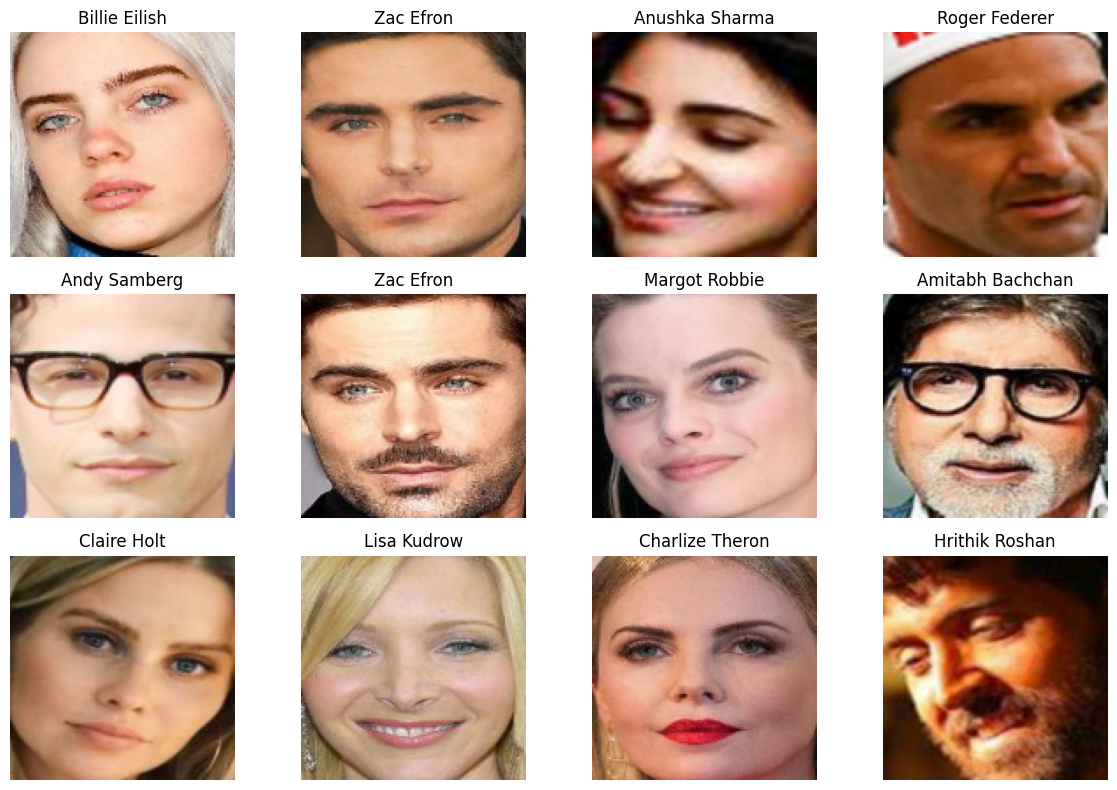

In [ ]:
plt.figure(figsize=(12, 8))

for images, labels in train_ds.take(1):
    
    for i in range(12):
        
        plt.subplot(3, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache().shuffle(1000).prefetch(
    buffer_size=AUTOTUNE
)

val_ds = val_ds.cache().prefetch(
    buffer_size=AUTOTUNE
)

In [ ]:
data_augmentation = keras.Sequential([
    
    layers.RandomFlip("horizontal"),
    
    layers.RandomRotation(0.08),
    
    layers.RandomZoom(0.10),
    
    layers.RandomContrast(0.10),
    
], name="data_augmentation")

In [ ]:
num_classes = len(class_names)

model = keras.Sequential([
    
    layers.Input(shape=(128, 128, 3)),
    
    data_augmentation,
    
    layers.Rescaling(1./255),
    
    # CNN Block 1
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D(),
    
    # CNN Block 2
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D(),
    
    # CNN Block 3
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D(),
    
    # CNN Block 4
    layers.Conv2D(256, (3, 3), activation="relu"),
    layers.MaxPooling2D(),
    
    # Classification
    layers.Flatten(),
    
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.5),
    
    layers.Dense(num_classes, activation="softmax")
])

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 12, 12, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     2,359,552 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 31)             │         7,967 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,755,935 (10.51 MB)

 Trainable params: 2,755,935 (10.51 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=60
)

Epoch 1/60
65/65 ━━━━━━━━━━━━━━━━━━━━ 46s 555ms/step - accuracy: 0.0415 - loss: 3.4279 - val_accuracy: 0.0527 - val_loss: 3.4169
Epoch 2/60
65/65 ━━━━━━━━━━━━━━━━━━━━ 30s 468ms/step - accuracy: 0.0376 - loss: 3.4139 - val_accuracy: 0.0293 - val_loss: 3.4189
Epoch 3/60
65/65 ━━━━━━━━━━━━━━━━━━━━ 29s 443ms/step - accuracy: 0.0351 - loss: 3.4024 - val_accuracy: 0.0605 - val_loss: 3.3947
Epoch 4/60
65/65 ━━━━━━━━━━━━━━━━━━━━ 27s 420ms/step - accuracy: 0.0844 - loss: 3.2834 - val_accuracy: 0.1562 - val_loss: 3.0390
Epoch 5/60
65/65 ━━━━━━━━━━━━━━━━━━━━ 29s 446ms/step - accuracy: 0.1537 - loss: 2.9893 - val_accuracy: 0.2324 - val_loss: 2.7072
Epoch 6/60
65/65 ━━━━━━━━━━━━━━━━━━━━ 28s 432ms/step - accuracy: 0.2005 - loss: 2.7640 - val_accuracy: 0.2617 - val_loss: 2.4522
Epoch 7/60
65/65 ━━━━━━━━━━━━━━━━━━━━ 28s 438ms/step - accuracy: 0.2327 - loss: 2.6158 - val_accuracy: 0.3320 - val_loss: 2.2871
Epoch 8/60
65/65 ━━━━━━━━━━━━━━━━━━━━ 31s 476ms/step - accuracy: 0.2571 - loss: 2.5249 - val_accu

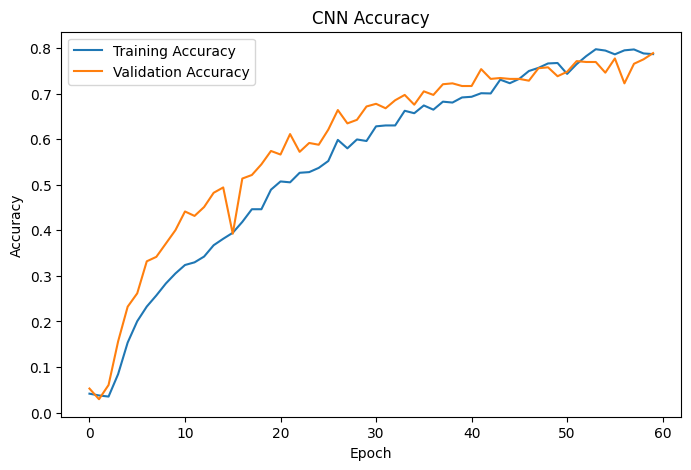

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Accuracy")

plt.legend()
plt.show()

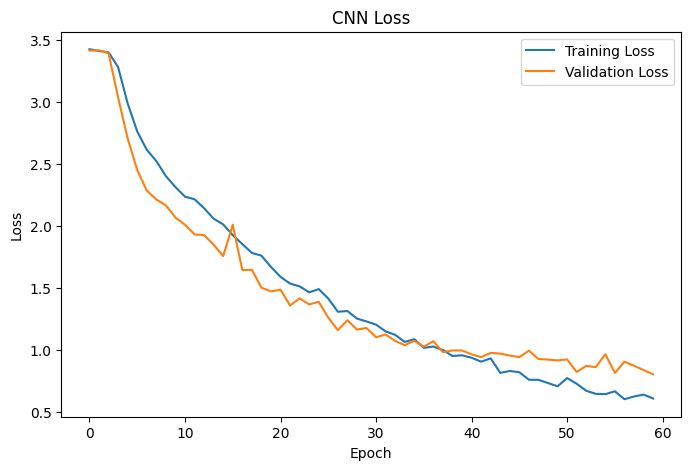

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Loss")

plt.legend()
plt.show()

In [ ]:
os.makedirs("saved_model", exist_ok=True)

In [ ]:
model.save("saved_model/face_recognition.keras")

In [ ]:
with open("saved_model/class_names.json", "w") as f:
    json.dump(class_names, f)

In [ ]:
def predict_face(image_path):
    
    img = tf.keras.utils.load_img(
        image_path,
        target_size=IMG_SIZE
    )
    
    img_array = tf.keras.utils.img_to_array(img)
    
    img_array = tf.expand_dims(img_array, 0)
    
    predictions = model.predict(img_array, verbose=0)
    
    predicted_index = np.argmax(predictions[0])
    
    confidence = predictions[0][predicted_index]
    
    predicted_name = class_names[predicted_index]
    
    return predicted_name, confidence

In [ ]:
def predict_face(image_path):
    
    img = tf.keras.utils.load_img(
        image_path,
        target_size=IMG_SIZE
    )
    
    img_array = tf.keras.utils.img_to_array(img)
    
    img_array = tf.expand_dims(img_array, 0)
    
    predictions = model.predict(img_array, verbose=0)
    
    predicted_index = np.argmax(predictions[0])
    
    confidence = predictions[0][predicted_index]
    
    predicted_name = class_names[predicted_index]
    
    return predicted_name, confidence

In [ ]:
image_path = "C:\Users\muham\Desktop\CV_Project\Faces\Tom Cruise\Tom Cruise_0.jpg"

name, confidence = predict_face(image_path)

print("Predicted:", name)
print("Confidence:", round(float(confidence) * 100, 2), "%")

SyntaxError: (unicode error) 'unicodeescape' codec can't decode bytes in position 2-3: truncated \UXXXXXXXX escape (101352609.py, line 1)